In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from numpy import mean

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

%matplotlib inline

In [2]:
fileName = r"C:\Users\justi\Downloads\Earthquake_Query_1.02 - Sheet1.csv"
pd.read_csv(fileName)

,time,date,year,latitude,longitude,depth,mag,Continent,magType,nst,...,Plates,Mechanism,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
0,2026-09-25T21:23:03.309Z,2026-09-25,2026,-21.2982,168.6100,10.000,6.6,Oceania,mww,102.0,...,NaN,NaN,earthquake,8.58,1.850,0.052,36.0,reviewed,us,us
1,2026-09-20T09:17:35.624Z,2026-09-20,2026,-5.9021,146.0922,104.329,6.4,Oceania,mww,91.0,...,NaN,NaN,earthquake,7.38,6.280,0.039,62.0,reviewed,us,us
2,2026-09-17T14:19:53.164Z,2026-09-17,2026,52.7648,-171.2950,111.666,6.5,North America,mww,146.0,...,NaN,NaN,earthquake,6.49,4.521,0.027,130.0,reviewed,us,us
3,2026-09-11T21:23:55.907Z,2026-09-11,2026,-4.9832,106.8742,372.000,6.5,Asia,mww,116.0,...,NaN,NaN,earthquake,9.17,1.949,0.043,51.0,reviewed,us,us
4,2026-09-03T11:17:24.056Z,2026-09-03,2026,52.2579,-169.4090,35.000,6.3,North America,mww,136.0,...,NaN,NaN,earthquake,4.37,1.870,0.031,102.0,reviewed,us,us
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14678,1692-06-07T16:50:00.000Z,1692-06-07,1692,18.0000,-76.5000,NaN,7.5,North America,mw,NaN,...,NaN,NaN,earthquake,NaN,NaN,NaN,NaN,reviewed,official,official
14679,1690-04-16T20:00:00.000Z,1690-04-16,1690,17.0800,-62.5100,NaN,7.5,North America,mint,NaN,...,NaN,NaN,earthquake,NaN,NaN,NaN,NaN,reviewed,official,official
14680,1663-02-05T22:30:00.000Z,1663-02-05,1663,47.6000,-70.1000,NaN,7.0,North America,mw,NaN,...,NaN,NaN,earthquake,NaN,NaN,NaN,NaN,reviewed,ushis,official
14681,1638-06-11T19:00:00.000Z,1638-06-11,1638,43.4000,-71.6000,NaN,6.5,North America,mlg,NaN,...,North American,NaN,earthquake,NaN,NaN,NaN,NaN,reviewed,official,official


In [3]:
df = pd.read_csv(fileName)
df.head()

,time,date,year,latitude,longitude,depth,mag,Continent,magType,nst,...,Plates,Mechanism,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
0,2026-09-25T21:23:03.309Z,2026-09-25,2026,-21.2982,168.6100,10.000,6.6,Oceania,mww,102.0,...,NaN,NaN,earthquake,8.58,1.850,0.052,36.0,reviewed,us,us
1,2026-09-20T09:17:35.624Z,2026-09-20,2026,-5.9021,146.0922,104.329,6.4,Oceania,mww,91.0,...,NaN,NaN,earthquake,7.38,6.280,0.039,62.0,reviewed,us,us
2,2026-09-17T14:19:53.164Z,2026-09-17,2026,52.7648,-171.2950,111.666,6.5,North America,mww,146.0,...,NaN,NaN,earthquake,6.49,4.521,0.027,130.0,reviewed,us,us
3,2026-09-11T21:23:55.907Z,2026-09-11,2026,-4.9832,106.8742,372.000,6.5,Asia,mww,116.0,...,NaN,NaN,earthquake,9.17,1.949,0.043,51.0,reviewed,us,us
4,2026-09-03T11:17:24.056Z,2026-09-03,2026,52.2579,-169.4090,35.000,6.3,North America,mww,136.0,...,NaN,NaN,earthquake,4.37,1.870,0.031,102.0,reviewed,us,us


In [4]:
df_mag = df['mag']
df_mag.head()

0    6.6
1    6.4
2    6.5
3    6.5
4    6.3
Name: mag, dtype: float64

In [5]:
names_dict = {'date': 'date', 'year': 'year', 'mag': 'mag', 'Country / Region': 'country', 'depth': 'depth'}

df = df.rename(columns = names_dict)
df.head()

,time,date,year,latitude,longitude,depth,mag,Continent,magType,nst,...,Plates,Mechanism,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
0,2026-09-25T21:23:03.309Z,2026-09-25,2026,-21.2982,168.6100,10.000,6.6,Oceania,mww,102.0,...,NaN,NaN,earthquake,8.58,1.850,0.052,36.0,reviewed,us,us
1,2026-09-20T09:17:35.624Z,2026-09-20,2026,-5.9021,146.0922,104.329,6.4,Oceania,mww,91.0,...,NaN,NaN,earthquake,7.38,6.280,0.039,62.0,reviewed,us,us
2,2026-09-17T14:19:53.164Z,2026-09-17,2026,52.7648,-171.2950,111.666,6.5,North America,mww,146.0,...,NaN,NaN,earthquake,6.49,4.521,0.027,130.0,reviewed,us,us
3,2026-09-11T21:23:55.907Z,2026-09-11,2026,-4.9832,106.8742,372.000,6.5,Asia,mww,116.0,...,NaN,NaN,earthquake,9.17,1.949,0.043,51.0,reviewed,us,us
4,2026-09-03T11:17:24.056Z,2026-09-03,2026,52.2579,-169.4090,35.000,6.3,North America,mww,136.0,...,NaN,NaN,earthquake,4.37,1.870,0.031,102.0,reviewed,us,us


In [6]:
columns_list = ['date', 'year','mag', 'country', 'depth']
df_subset = df[columns_list]
df_subset.head()

,date,year,mag,country,depth
0,2026-09-25,2026,6.6,New Caledonia,10.000
1,2026-09-20,2026,6.4,Papua New Guinea,104.329
2,2026-09-17,2026,6.5,US - Alaska,111.666
3,2026-09-11,2026,6.5,Indonesia,372.000
4,2026-09-03,2026,6.3,US - Alaska,35.000


In [7]:
df_subset['year'] = pd.to_numeric(df_subset['year'], errors='coerce')

pre_1950 = df_subset['year'] < 1950

print(pre_1950)

0        False
1        False
2        False
3        False
4        False
         ...  
14678     True
14679     True
14680     True
14681     True
14682     True
Name: year, Length: 14683, dtype: bool


In [8]:
pre_1950_df = df_subset[pre_1950]
pre_1950_df

,date,year,mag,country,depth
10489,1949-12-29,1949,7.21,Philippines,15.0
10490,1949-12-27,1949,6.68,South Sandwich Islands,10.0
10491,1949-12-26,1949,6.92,Fiji,15.0
10492,1949-12-25,1949,6.31,Japan,10.0
10493,1949-12-25,1949,6.29,Japan,10.0
...,...,...,...,...,...
14678,1692-06-07,1692,7.50,Jamaica,NaN
14679,1690-04-16,1690,7.50,Leeward Islands,NaN
14680,1663-02-05,1663,7.00,CA - Quebec,NaN
14681,1638-06-11,1638,6.50,US - New Hampshire,NaN


In [9]:
post_1950 = df_subset['year'] > 1950
post_1950_df = df_subset[post_1950]
post_1950_df.head()

,date,year,mag,country,depth
0,2026-09-25,2026,6.6,New Caledonia,10.000
1,2026-09-20,2026,6.4,Papua New Guinea,104.329
2,2026-09-17,2026,6.5,US - Alaska,111.666
3,2026-09-11,2026,6.5,Indonesia,372.000
4,2026-09-03,2026,6.3,US - Alaska,35.000


In [10]:
# isolate CO2 columns.
pre1950_mag = pre_1950_df['mag']
post1950_mag = post_1950_df['mag']

pre_1950_mean = pre1950_mag.mean()
post_1950_mean = post1950_mag.mean()

# Don't touch: this computes the higher mean value.
max_val = max(pre_1950_mean, post_1950_mean)
min_val = min(pre_1950_mean, post_1950_mean)
prep_list = ['pre', 'post']
print(f'{prep_list[np.argmax([pre_1950_mean, post_1950_mean])]}-1950 mean is higher,\nwith a value of {max_val} mag vs. {min_val} mag.')

pre-1950 mean is higher,
with a value of 6.511056270863137 mag vs. 6.378580937680879 mag.


Text(0.5, 1.0, 'Magnitude Per Year')

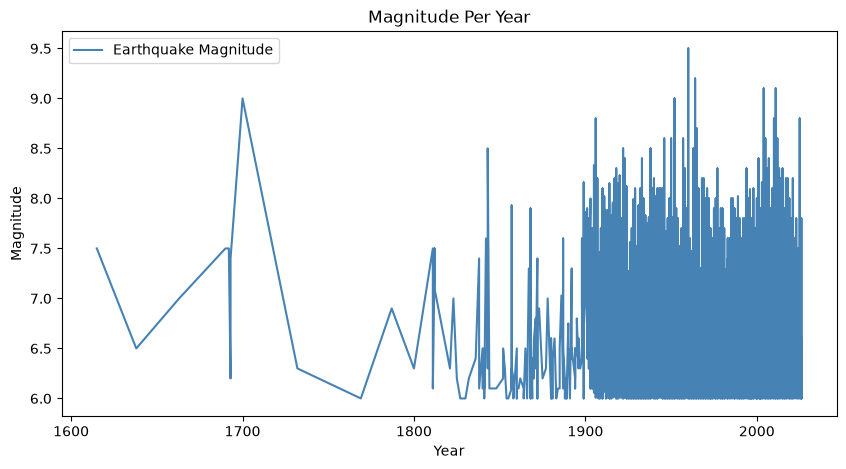

In [11]:
fig, ax = plt.subplots(figsize=(10,5))

x_data = df_subset['year']
y_data = df_subset['mag']

plt.plot(x_data , y_data, color='steelblue', label='Earthquake Magnitude')
plt.legend()

plt.xlabel('Year')
plt.ylabel('Magnitude')
plt.title('Magnitude Per Year')

In [12]:
yearly_summary = (df.groupby("year", as_index=False).agg(number_of_events=("id", "count"), average_magnitude=("mag", "mean")))

yearly_summary = yearly_summary[yearly_summary["number_of_events"] >= 5]

yearly_summary["average_magnitude"] = (yearly_summary["average_magnitude"].round(3))

print(yearly_summary)

     year  number_of_events  average_magnitude
11   1811                 5              6.640
31   1857                 5              6.546
40   1868                14              6.407
44   1872                 7              6.600
56   1887                 5              6.560
..    ...               ...                ...
190  2022               127              6.371
191  2023               147              6.414
192  2024                99              6.364
193  2025               145              6.390
194  2026               102              6.369

[133 rows x 3 columns]


In [13]:
yearly_summary = (df.groupby("year", as_index=False).agg(number_of_events=("id", "count"), average_magnitude=("mag", "mean")))

yearly_summary = yearly_summary[yearly_summary["number_of_events"] >= 5]

yearly_summary["average_magnitude"] = (yearly_summary["average_magnitude"].round(3))

summary_statistics = (yearly_summary[["number_of_events", "average_magnitude"]].agg(["max", "min", "mean", "median"]).rename(index=
{"max": "High", "min": "Low", "mean": "Mean", "median": "Median"}).round(3))

print(yearly_summary)
print("\nSummary statistics:")
print(summary_statistics)

     year  number_of_events  average_magnitude
11   1811                 5              6.640
31   1857                 5              6.546
40   1868                14              6.407
44   1872                 7              6.600
56   1887                 5              6.560
..    ...               ...                ...
190  2022               127              6.371
191  2023               147              6.414
192  2024                99              6.364
193  2025               145              6.390
194  2026               102              6.369

[133 rows x 3 columns]

Summary statistics:
        number_of_events  average_magnitude
High             207.000              7.258
Low                5.000              6.314
Mean             109.579              6.469
Median           113.000              6.399


In [14]:
highest_year = yearly_summary.loc[yearly_summary["number_of_events"].idxmax(), ["year", "number_of_events"]]

highest_average = yearly_summary.loc[yearly_summary["average_magnitude"].idxmax(), ["year", "average_magnitude"]]

lowest_years = yearly_summary.loc[yearly_summary["number_of_events"] == 5,["year", "number_of_events"]]

print("Year with the highest number of events:")
print(highest_year)

print("\nYear with the highest average magnitude:")
print(highest_average)

print("\nYear(s) with the lowest count of 5 events:")
print(lowest_years.to_string(index=False))

Year with the highest number of events:
year                2011
number_of_events     207
Name: 179, dtype: int64

Year with the highest average magnitude:
year                 1900.000
average_magnitude       7.258
Name: 68, dtype: float64

Year(s) with the lowest count of 5 events:
 year  number_of_events
 1811                 5
 1857                 5
 1887                 5


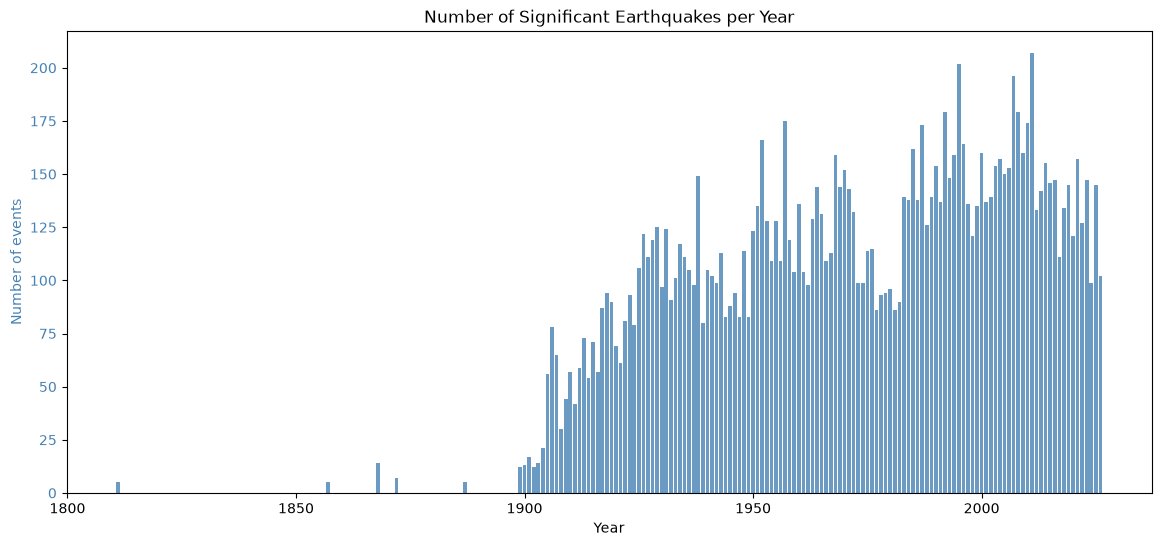

In [15]:
fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.bar(
    yearly_summary["year"],
    yearly_summary["number_of_events"],
    color="steelblue",
    alpha=0.8
)

ax1.set_xlabel("Year")
ax1.set_ylabel("Number of events", color="steelblue")
ax1.set_title("Number of Significant Earthquakes per Year")
ax1.tick_params(axis="y", labelcolor="steelblue")


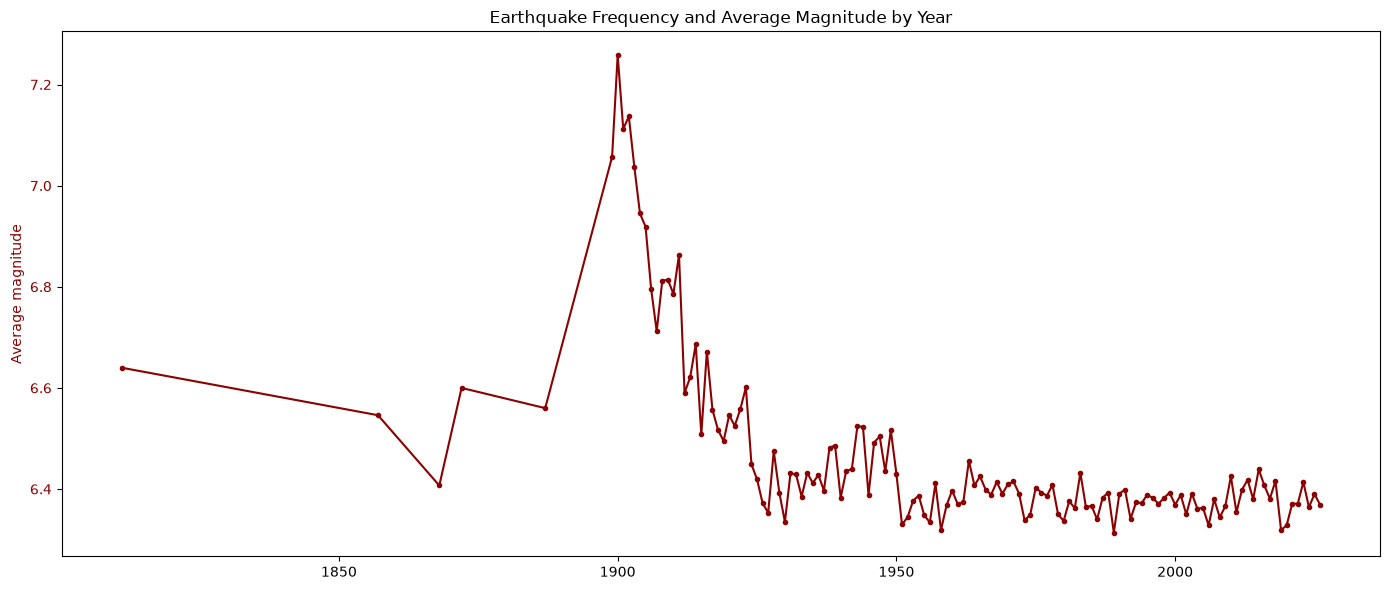

In [16]:
fig, ax2 = plt.subplots(figsize=(14, 6))
ax2.plot(
    yearly_summary["year"],
    yearly_summary["average_magnitude"],
    color="darkred",
    marker="o",
    markersize=3,
    linewidth=1.5
)

ax2.set_ylabel("Average magnitude", color="darkred")
ax2.tick_params(axis="y", labelcolor="darkred")

plt.title("Earthquake Frequency and Average Magnitude by Year")
fig.tight_layout()
plt.show()

In [17]:
FRAC = 0.1
df_ = pd.read_csv(r"C:\Users\justi\Downloads\Earthquake_Query_1.02 - Sheet1.csv").sample(frac=FRAC, random_state=42)
df.head()

,time,date,year,latitude,longitude,depth,mag,Continent,magType,nst,...,Plates,Mechanism,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
0,2026-09-25T21:23:03.309Z,2026-09-25,2026,-21.2982,168.6100,10.000,6.6,Oceania,mww,102.0,...,NaN,NaN,earthquake,8.58,1.850,0.052,36.0,reviewed,us,us
1,2026-09-20T09:17:35.624Z,2026-09-20,2026,-5.9021,146.0922,104.329,6.4,Oceania,mww,91.0,...,NaN,NaN,earthquake,7.38,6.280,0.039,62.0,reviewed,us,us
2,2026-09-17T14:19:53.164Z,2026-09-17,2026,52.7648,-171.2950,111.666,6.5,North America,mww,146.0,...,NaN,NaN,earthquake,6.49,4.521,0.027,130.0,reviewed,us,us
3,2026-09-11T21:23:55.907Z,2026-09-11,2026,-4.9832,106.8742,372.000,6.5,Asia,mww,116.0,...,NaN,NaN,earthquake,9.17,1.949,0.043,51.0,reviewed,us,us
4,2026-09-03T11:17:24.056Z,2026-09-03,2026,52.2579,-169.4090,35.000,6.3,North America,mww,136.0,...,NaN,NaN,earthquake,4.37,1.870,0.031,102.0,reviewed,us,us


In [18]:
print(df.shape)                             
print('Occurrences of each Continent:')
print(df['Continent'].value_counts().sort_index())

(14683, 33)
Occurrences of each Continent:
Continent
Africa            155
Antarctica        328
Asia             5746
Europe            280
Mid-Atlantic      553
North America    2158
Oceania          4083
South America    1380
Name: count, dtype: int64


In [19]:
X = df.drop(columns='Continent')
y = df['Continent']
test_fraction = 0.2

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

In [20]:
for frame in (X_train, X_test):
    frame["time"] = pd.to_datetime(frame["time"], errors="coerce", utc=True)

    frame["event_month"] = frame["time"].dt.month
    frame["event_day"] = frame["time"].dt.day
    frame["event_hour"] = frame["time"].dt.hour

drop_columns = [
    "time",
    "date",
    "updated",
    "id",
    "Executive",
    "PAGER",
    "place",
    "place.1",
    "Unnamed: 20",
    "Mechanism"
]

X_train = X_train.drop(columns=drop_columns, errors="ignore")
X_test = X_test.drop(columns=drop_columns, errors="ignore")

numeric_columns = X_train.select_dtypes(include="number").columns
categorical_columns = X_train.select_dtypes(exclude="number").columns

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)

In [21]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](8,)","['Africa','Antarctica','Asia',...,'North America','Oceania', 'South America']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](25,)","['year','latitude','longitude',...,'event_month','event_day','event_hour']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,25
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifie

In [22]:
y_pred = rf_model.predict(X_test)

preds_equal_true = y_pred == y_test
accuracy = (y_pred == y_test).mean()
print(f'Overall test accuracy: {accuracy:.3f}')

Overall test accuracy: 0.991


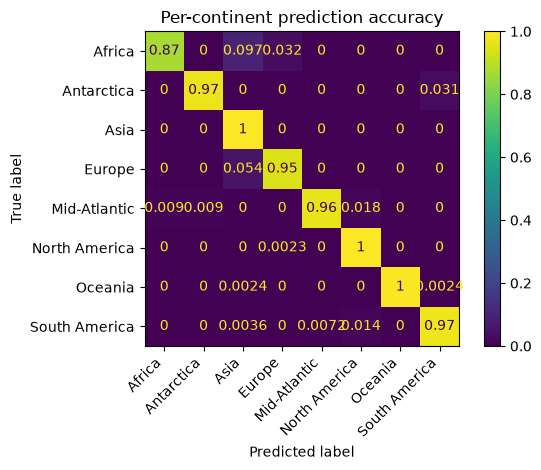

In [23]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, normalize='true')
plt.title('Per-continent prediction accuracy')

plt.title("Per-continent prediction accuracy")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

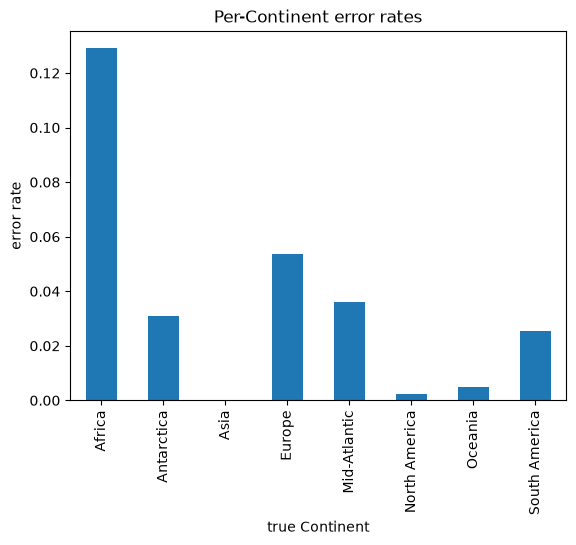

In [24]:
wrong = pd.Series(y_pred != y_test.values, index=y_test.index)
wrong.groupby(y_test).mean().plot.bar()
plt.xlabel('true Continent')
plt.ylabel('error rate')
plt.title('Per-Continent error rates');

In [25]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=42)

In [26]:
n_trees_list = [10, 25, 50, 100, 200, 300]
val_acc = []

for n_trees in n_trees_list:
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=n_trees,
            random_state=42,
            n_jobs=-1
        ))
    ])

    model.fit(X_tr, y_tr)
    score = model.score(X_val, y_val)
    val_acc.append(score)

    print(f"{n_trees} trees: {score:.3f}")

print("\nn_trees_list:", n_trees_list)
print("val_acc:", val_acc)
print("Lengths:", len(n_trees_list), len(val_acc))    

10 trees: 0.988
25 trees: 0.990
50 trees: 0.991
100 trees: 0.990
200 trees: 0.990
300 trees: 0.991

n_trees_list: [10, 25, 50, 100, 200, 300]
val_acc: [0.9880830779707184, 0.9897854954034729, 0.9908069458631257, 0.9901259788900239, 0.9901259788900239, 0.9911474293496766]
Lengths: 6 6


In [27]:
print("Tree counts:", len(n_trees_list))
print("Accuracy values:", len(val_acc))

best_tree_index = val_acc.index(max(val_acc))
best_n = n_trees_list[best_tree_index]

print("Best number of trees:", best_n)
print(f"Best validation accuracy: {val_acc[best_tree_index]:.3f}")

Tree counts: 6
Accuracy values: 6
Best number of trees: 300
Best validation accuracy: 0.991


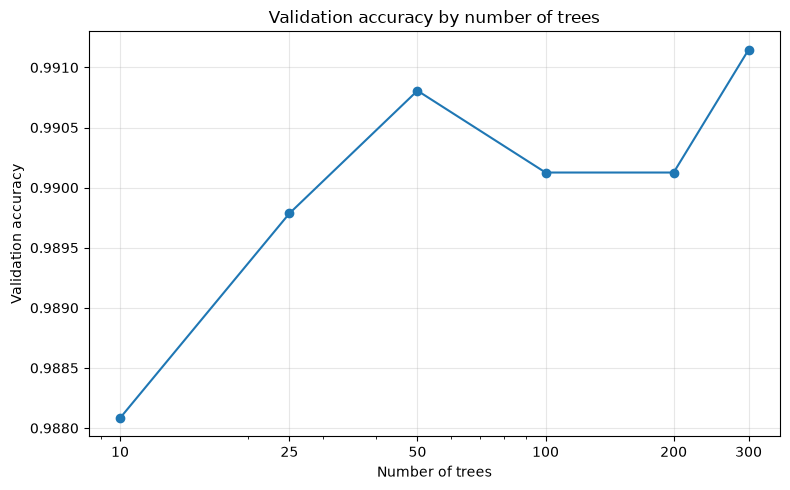

In [28]:
plt.figure(figsize=(8, 5))
plt.plot(n_trees_list, val_acc, marker="o")

plt.xscale("log")
plt.xticks(n_trees_list, labels=n_trees_list)
plt.xlabel("Number of trees")
plt.ylabel("Validation accuracy")
plt.title("Validation accuracy by number of trees")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
best_n = n_trees_list[best_tree_index]
print("Best number of trees:", best_n)

rf_best = Pipeline([
("preprocessor", preprocessor), ("classifier", RandomForestClassifier(n_estimators=best_n, random_state=42, n_jobs=-1))])

rf_best.fit(X_train, y_train)

accuracy_100 = rf_model.score(X_test, y_test)
accuracy_best = rf_best.score(X_test, y_test)

print(
f"Test accuracy: {accuracy_100:.3f} (100 trees) "f"vs {accuracy_best:.3f} ({best_n} trees)")

Best number of trees: 300
Test accuracy: 0.991 (100 trees) vs 0.992 (300 trees)


In [30]:
cap = 10000
train = X_train.assign(Continent=y_train)
balanced = train.groupby('Continent').head(cap)
X_bal, y_bal = balanced.drop(columns='Continent'), balanced['Continent']
print(y_bal.value_counts().sort_index())

Continent
Africa            124
Antarctica        263
Asia             4597
Europe            224
Mid-Atlantic      442
North America    1726
Oceania          3266
South America    1104
Name: count, dtype: int64


In [31]:
rf_bal = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))])

rf_bal.fit(X_bal, y_bal)

y_pred_bal = rf_bal.predict(X_test)

print
(f"Overall accuracy: original {(y_pred == y_test).mean():.3f}, "
f"undersampled {(y_pred_bal == y_test).mean():.3f}")

'Overall accuracy: original 0.991, undersampled 0.991'

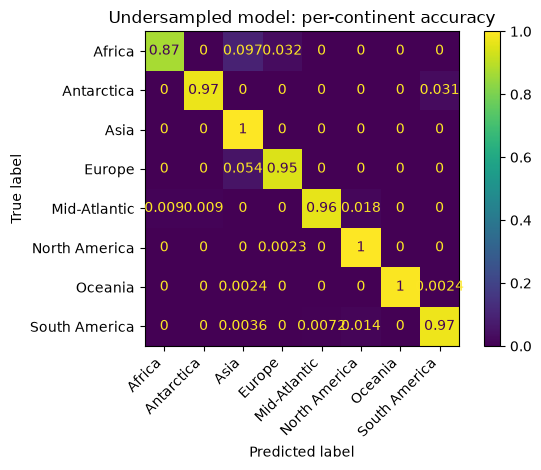

In [32]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_bal, normalize="true")

plt.title("Undersampled model: per-continent accuracy")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()